# Machine Learning — Deliverable 2
## Quem vai usar cada ferramenta de IA no próximo mês?

**DAMA Intelligence** · Ana Luiza Proença, Gustavo Gomes, Kaique Lira e Ricardo Matteo · Ciência de Dados e Negócios, ESPM, 4º semestre, 2026

Este notebook treina, valida e avalia um modelo que estima, para cada **colaborador × ferramenta de IA por assento**, a probabilidade de uso no mês seguinte. A probabilidade alimenta duas decisões do DAMA:

- **Recomendação de licenças:** quem deve receber, manter ou devolver cada assento. É a mesma pergunta do modelo de [Pesquisa Operacional](../Pesquisa%20Operacional/), agora com o valor **previsto** em vez do valor histórico.
- **Alertas de gestão:** licença que deve ficar ociosa ou colaborador que deve deixar de usar IA.

## 1. Do Deliverable 1 ao Deliverable 2

No D1 (`Deliverable1/machine-learning-ia/main.ipynb`), o modelo classificava quem tinha **alto uso de IA** no período inteiro (acima do percentil 75 de requisições), com regressão logística sobre cargo, senioridade, departamento, setor, porte e tempo de casa. A versão balanceada chegou a recall de 0,80 e precisão de 0,43 na classe de alto uso.

Esse desenho tinha quatro limites, corrigidos em `main_corrigido.ipynb`:

1. O alvo somava 14 meses de uso, então quem foi contratado depois tinha menos meses para acumular requisições. O alvo media em parte o **tempo de exposição**, não a intensidade.
2. `tenure_days` entrava sem escalonamento na regressão logística. Por isso os coeficientes não eram comparáveis entre si.
3. Uma única divisão treino/teste, sem estratificação nem validação cruzada.
4. Só um algoritmo, sem baseline e sem métricas de ranqueamento (ROC-AUC, PR-AUC).

O D2 muda a pergunta para uma que o produto usa: **no mês seguinte, este colaborador vai usar esta ferramenta?** A unidade passa a ser colaborador × ferramenta × mês. O modelo usa o **histórico de uso**, que o D1 ignorava, e a validação é **temporal**: treina no passado e testa no futuro, como o modelo seria usado de verdade.

## 2. Configuração

In [1]:
import re
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

warnings.filterwarnings('ignore', category=pd.errors.DtypeWarning)
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)

DADOS = Path('../../Deliverable1/machine-learning-ia/Data/csv')   # base sintética do projeto (mesma da Estatística e da PO)
SAIDA = Path('resultados'); SAIDA.mkdir(exist_ok=True)
FIG = Path('figuras'); FIG.mkdir(exist_ok=True)
SEED = 42

MESES = pd.period_range('2025-06', '2026-07', freq='M')
FIM_TREINO = pd.Period('2026-03', 'M')       # meses-alvo de jul/2025 a mar/2026
VALIDACAO = [pd.Period('2026-04', 'M'), pd.Period('2026-05', 'M')]
TESTE = [pd.Period('2026-06', 'M'), pd.Period('2026-07', 'M')]
ORDEM_SENIORIDADE = ['Junior', 'Pleno', 'Senior', 'Especialista', 'Gerente']

# paleta do projeto (a mesma da Pesquisa Operacional); texto sempre em tinta neutra
AZUL, LARANJA, VERDE, AMARELO = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
CINZA = '#8f8e89'
TINTA, TINTA2, GRADE, FUNDO = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
plt.rcParams.update({
    'figure.facecolor': FUNDO, 'axes.facecolor': FUNDO, 'axes.edgecolor': GRADE, 'axes.labelcolor': TINTA2,
    'xtick.color': TINTA2, 'ytick.color': TINTA2, 'text.color': TINTA, 'axes.grid': True, 'grid.color': GRADE,
    'grid.linewidth': 0.8, 'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 2,
    'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'bold', 'legend.frameon': False
})
inicio = time.time()

## 3. Dados e diagnóstico da base

Na pré-avaliação do D1, os professores pediram um diagnóstico explícito da base (tarefas SMAN-65 e SMAN-154 a 159). Para cada tabela usada, o diagnóstico mede dimensões, nulos, cardinalidade, duplicatas e ausências disfarçadas: textos vazios, "N/A" e valores negativos onde não cabem.

In [2]:
ler = lambda nome, **kw: pd.read_csv(DADOS / f'{nome}.csv', **kw)
emp, dep, comp = ler('employees'), ler('departments'), ler('companies')
tools, lic, appr, trein = ler('ai_tools'), ler('ai_licenses'), ler('approved_ai_tools'), ler('training_records')
uso = ler('ai_usage_logs', usecols=['usage_id', 'timestamp', 'employee_id', 'company_id', 'ai_tool_id', 'request_count', 'request_status'])

def diagnostico(nome, df):
    texto = df.select_dtypes(include=['object', 'string'])
    disfarcados = int(sum(texto[c].astype('string').str.strip().str.upper().isin(['', 'N/A', 'NA', 'NULL', 'NONE', '-']).sum() for c in texto))
    numericas = df.select_dtypes('number')
    negativos = int((numericas < 0).sum().sum()) if len(numericas.columns) else 0
    cat = {c: df[c].nunique() for c in texto.columns if not c.endswith('_id') and c not in ('timestamp',)}
    return dict(tabela=nome, linhas=len(df), colunas=df.shape[1], celulas_nulas=int(df.isna().sum().sum()),
                colunas_com_nulos=', '.join(f'{c} ({df[c].isna().mean():.1%})' for c in df.columns if df[c].isna().any()) or '—',
                linhas_duplicadas=int(df.duplicated().sum()), ausencias_disfarcadas=disfarcados, numeros_negativos=negativos,
                cardinalidade=', '.join(f'{c}: {n}' for c, n in cat.items()) or '—')

diag = pd.DataFrame([diagnostico(n, d) for n, d in [('employees', emp), ('departments', dep), ('companies', comp), ('ai_tools', tools),
                     ('ai_licenses', lic), ('approved_ai_tools', appr), ('training_records', trein), ('ai_usage_logs', uso)]])
diag.to_csv(SAIDA / 'diagnostico_base.csv', index=False)
diag

,tabela,linhas,colunas,celulas_nulas,colunas_com_nulos,linhas_duplicadas,ausencias_disfarcadas,numeros_negativos,cardinalidade
0,employees,2356,8,45,cost_center (1.9%),0,0,0,"job_role: 75, seniority: 5, hire_date: 1423, c..."
1,departments,161,3,0,—,0,0,0,department_name: 31
2,companies,18,5,0,—,0,0,0,"company_name: 18, industry: 6, company_size: 3"
3,ai_tools,15,5,0,—,0,0,0,"tool_name: 15, provider: 11, tool_category: 5,..."
4,ai_licenses,5605,7,1574,expiration_date (28.1%),0,0,0,"license_type: 3, assigned_date: 367, expiratio..."
5,approved_ai_tools,105,5,48,allowed_departments (45.7%),0,0,0,"approval_status: 3, approval_date: 77, allowed..."
6,training_records,1597,10,1356,"completion_date (42.5%), score (42.5%)",0,0,0,"course_name: 12, course_category: 8, enrollmen..."
7,ai_usage_logs,269515,7,0,—,0,0,0,request_status: 4


**Leitura do diagnóstico e tratamento adotado.**

| Achado | Tratamento |
|---|---|
| Nenhuma linha duplicada, nenhum texto vazio ou "N/A" e nenhum número negativo | Nada a fazer |
| `expiration_date` nula em 28% das licenças | Não é ausência: são contratos sem data de fim. A licença conta como vigente enquanto não for atribuída depois do mês |
| `allowed_departments` nula quando a ferramenta não está aprovada; separador às vezes `,`, às vezes `;` | Nulo vira "nenhum departamento liberado"; os dois separadores são normalizados antes de comparar com o nome do departamento |
| `completion_date` e `score` nulos fora de "Concluido" | Esperado: só conta curso concluído até o mês de referência |
| `cost_center` nulo em 1,9% dos colaboradores | Não é usado no modelo |
| Cardinalidade: 75 cargos e 31 nomes de departamento | Cargo fica de fora: é quase sinônimo do departamento e geraria 75 colunas com poucas linhas cada. O departamento entra com one-hot, agrupando categorias com menos de 20 linhas |

Um ponto da base precisa ser conhecido antes de modelar: **licença e uso não andam juntos.** A conta abaixo mostra quanto do uso de ferramentas por assento vem de quem não tem licença daquela ferramenta.

In [3]:
assento = set(tools.loc[tools.licensing_type.str.startswith('Por'), 'ai_tool_id'])
u_assento = uso[uso.ai_tool_id.isin(assento)]
tem_alguma = set(zip(lic.employee_id, lic.ai_tool_id))
sem_licenca = ~pd.Series(list(zip(u_assento.employee_id, u_assento.ai_tool_id)), index=u_assento.index).isin(tem_alguma)
print(f'Eventos de uso de ferramentas por assento: {len(u_assento):,}'.replace(',', '.'))
print(f'Sem nenhuma licença do colaborador para a ferramenta: {sem_licenca.mean():.1%} ({u_assento[sem_licenca].employee_id.nunique()} colaboradores)')

Eventos de uso de ferramentas por assento: 262.913
Sem nenhuma licença do colaborador para a ferramenta: 34.6% (628 colaboradores)


Mais de um terço do uso vem de quem não tem licença registrada. Numa empresa real, isso seria conta compartilhada ou cadastro de licenças desatualizado. Para o modelo, a consequência é que **ter licença não indica uso**, e a seção 7 confirma isso. Por isso a recomendação considera todos os colaboradores da empresa, com ou sem licença.

## 4. Unidade de análise e alvo

- **Linha:** colaborador ativo × ferramenta por assento usada ou licenciada pela empresa × mês de referência *m*, a partir do mês de contratação.
- **Alvo:** `usa_proximo_mes` = 1 se o colaborador registrou pelo menos um evento da ferramenta no mês *m*+1.
- **Por que só ferramentas por assento:** são as que têm licença para distribuir. As de consumo (APIs e plataformas) são cobradas por token e não precisam de assento.
- **Por que só colaboradores ativos:** a base não traz data de desligamento, então não dá para saber até quando um inativo trabalhou. Como a recomendação é para o mês seguinte, só ativos importam.

**Regra contra vazamento:** toda variável da linha *m* usa só informação disponível até o fim do mês *m*.

In [4]:
uso['mes'] = pd.to_datetime(uso.timestamp).dt.to_period('M')
emp_at = emp[emp.active].copy()
emp_at['mes_contratacao'] = pd.to_datetime(emp_at.hire_date).dt.to_period('M')

adotadas = pd.concat([uso[['company_id', 'ai_tool_id']], lic[['company_id', 'ai_tool_id']]]).drop_duplicates()
adotadas = adotadas[adotadas.ai_tool_id.isin(assento)]

grade = (emp_at[['employee_id', 'company_id', 'department_id', 'seniority', 'mes_contratacao']]
         .merge(adotadas, on='company_id')
         .merge(pd.DataFrame({'mes': MESES}), how='cross'))
grade = grade[grade.mes >= grade.mes_contratacao].copy()

# uso mensal por colaborador × ferramenta
mensal = (uso[uso.ai_tool_id.isin(assento)].groupby(['employee_id', 'ai_tool_id', 'mes'])
          .agg(eventos=('usage_id', 'size'), requisicoes=('request_count', 'sum')).reset_index())
g = grade.merge(mensal, on=['employee_id', 'ai_tool_id', 'mes'], how='left').fillna({'eventos': 0, 'requisicoes': 0})
g = g.sort_values(['employee_id', 'ai_tool_id', 'mes']).reset_index(drop=True)
par = g.groupby(['employee_id', 'ai_tool_id'], sort=False)
g['usou'] = (g.eventos > 0).astype(int)
g['usa_proximo_mes'] = par.usou.shift(-1)
print(f'Pares colaborador × ferramenta: {g.groupby(["employee_id", "ai_tool_id"]).ngroups:,}'.replace(',', '.'))
print(f'Linhas (par × mês): {len(g):,}'.replace(',', '.'))

Pares colaborador × ferramenta: 6.821
Linhas (par × mês): 90.161


## 5. Variáveis

| Grupo | Variável | O que mede |
|---|---|---|
| Histórico da ferramenta | `log_req_m0`, `log_req_m1`, `log_req_m2` | log(1 + requisições) da ferramenta em *m*, *m*−1 e *m*−2 |
| | `meses_uso_3` | Meses com uso entre *m*−2 e *m* (0 a 3) |
| | `meses_uso_total` | Meses com uso desde o início da série |
| | `meses_desde_ultimo_uso`, `nunca_usou` | Recência do último uso; quem nunca usou recebe o maior valor possível e a marcação |
| Uso geral de IA | `log_req_total_m0`, `log_req_total_3m`, `ferramentas_m0` | Uso de **todas** as ferramentas (inclusive as de consumo) no mês e nos últimos 3 meses |
| Contexto | `taxa_departamento` | Fração dos colegas do departamento (sem a própria pessoa) que usaram a ferramenta em *m* |
| | `licenca_vigente` | Licença da ferramenta vigente em *m*, pelas datas de atribuição e expiração |
| | `liberada_para_departamento` | Ferramenta aprovada pela governança para o departamento |
| | `cursos_concluidos` | Cursos de IA concluídos até *m* |
| | `meses_de_casa`, `meses_observados` | Tempo de casa e meses de histórico disponíveis |
| Calendário | `mes_alvo_ferias` | O mês *m*+1 é dezembro, janeiro ou julho (férias) |
| Categóricas | `seniority`, `tool_category`, `ai_tool_id`, `industry`, `company_size`, `department_name` | Perfil da pessoa, da ferramenta e da empresa |

In [5]:
for k in range(3):
    g[f'log_req_m{k}'] = np.log1p(par.requisicoes.shift(k).fillna(0))
g['meses_uso_3'] = par.usou.transform(lambda s: s.rolling(3, min_periods=1).sum())
g['meses_uso_total'] = par.usou.cumsum()
g['meses_observados'] = par.cumcount() + 1
g['_ultimo'] = np.where(g.usou == 1, g.meses_observados, np.nan)
g['_ultimo'] = par._ultimo.ffill()
g['nunca_usou'] = g._ultimo.isna().astype(int)
g['meses_desde_ultimo_uso'] = (g.meses_observados - g._ultimo).fillna(14)   # 14 = acima do maior histórico possível
g = g.drop(columns='_ultimo')

total = uso.groupby(['employee_id', 'mes']).agg(req_total=('request_count', 'sum'), ferramentas_m0=('ai_tool_id', 'nunique')).reset_index()
g = g.merge(total, on=['employee_id', 'mes'], how='left').fillna({'req_total': 0, 'ferramentas_m0': 0})
g['log_req_total_m0'] = np.log1p(g.req_total)
g = g.sort_values(['employee_id', 'ai_tool_id', 'mes']).reset_index(drop=True)
g['log_req_total_3m'] = np.log1p(g.groupby(['employee_id', 'ai_tool_id'], sort=False).req_total.transform(lambda s: s.rolling(3, min_periods=1).sum()))

depto = g.groupby(['department_id', 'ai_tool_id', 'mes']).agg(n=('usou', 'size'), usaram=('usou', 'sum')).reset_index()
g = g.merge(depto, on=['department_id', 'ai_tool_id', 'mes'])
g['taxa_departamento'] = (g.usaram - g.usou) / (g.n - 1).clip(lower=1)

lic['_ini'] = pd.to_datetime(lic.assigned_date).dt.to_period('M')
lic['_fim'] = pd.to_datetime(lic.expiration_date).dt.to_period('M')
g = g.merge(lic[['employee_id', 'ai_tool_id', '_ini', '_fim']], on=['employee_id', 'ai_tool_id'], how='left')
g['licenca_vigente'] = (g._ini.notna() & (g._ini <= g.mes) & (g._fim.isna() | (g._fim >= g.mes))).astype(int)

def departamentos_liberados(texto):
    if pd.isna(texto):
        return set()
    return {'*'} if texto.startswith('Todos') else {p.strip() for p in re.split('[;,]', texto)}
appr['_lib'] = appr.allowed_departments.map(departamentos_liberados)
g = g.merge(dep[['department_id', 'department_name']], on='department_id').merge(appr[['company_id', 'ai_tool_id', '_lib']], on=['company_id', 'ai_tool_id'], how='left')
g['liberada_para_departamento'] = [int(isinstance(l, set) and ('*' in l or d in l)) for l, d in zip(g._lib, g.department_name)]

concl = trein[trein.completion_status == 'Concluido'].assign(mes=lambda d: pd.to_datetime(d.completion_date).dt.to_period('M'))
cursos = concl.groupby(['employee_id', 'mes']).size().rename('c').reset_index()
g = g.merge(cursos, on=['employee_id', 'mes'], how='left').fillna({'c': 0}).sort_values(['employee_id', 'ai_tool_id', 'mes'])
antes = concl[concl.mes < MESES[0]].groupby('employee_id').size()                 # cursos concluídos antes da série
g['cursos_concluidos'] = g.groupby(['employee_id', 'ai_tool_id']).c.cumsum() + g.employee_id.map(antes).fillna(0)

g['meses_de_casa'] = (g.mes - g.mes_contratacao).apply(lambda x: x.n)
g['mes_alvo'] = g.mes + 1
g['mes_alvo_ferias'] = g.mes_alvo.dt.month.isin([12, 1, 7]).astype(int)
g = (g.merge(tools[['ai_tool_id', 'tool_category']], on='ai_tool_id')
      .merge(comp[['company_id', 'industry', 'company_size']], on='company_id'))

NUM = ['log_req_m0', 'log_req_m1', 'log_req_m2', 'meses_uso_3', 'meses_uso_total', 'meses_desde_ultimo_uso', 'nunca_usou',
       'log_req_total_m0', 'log_req_total_3m', 'ferramentas_m0', 'taxa_departamento', 'licenca_vigente',
       'liberada_para_departamento', 'cursos_concluidos', 'meses_de_casa', 'meses_observados', 'mes_alvo_ferias']
NOM = ['tool_category', 'ai_tool_id', 'industry', 'company_size', 'department_name']
ORD = ['seniority']
COLS = NUM + NOM + ORD

futuro = g[g.mes == MESES[-1]].copy()          # linhas de jul/2026: base da recomendação para ago/2026
base = g[g.usa_proximo_mes.notna()].copy()
base['usa_proximo_mes'] = base.usa_proximo_mes.astype(int)
print(f'Linhas com alvo: {len(base):,}'.replace(',', '.'), f'| taxa de uso no mês seguinte: {base.usa_proximo_mes.mean():.1%}')
base.groupby('mes_alvo').usa_proximo_mes.agg(['size', 'mean']).rename(columns={'size': 'linhas', 'mean': 'taxa_de_uso'}).T.round(3)

Linhas com alvo: 83.340 | taxa de uso no mês seguinte: 43.7%


mes_alvo,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07
linhas,5834.000,5954.000,6071.000,6176.000,6287.000,6366.000,6461.000,6551.000,6610.000,6669.000,6736.000,6804.00,6821.000
taxa_de_uso,0.354,0.407,0.415,0.416,0.436,0.398,0.439,0.462,0.464,0.468,0.467,0.47,0.461


A taxa de uso no mês seguinte fica perto de 44%, então **as classes não são desbalanceadas**: não é preciso `class_weight` nem reamostragem. A queda em dezembro e janeiro, e em menor grau em julho, é o efeito das férias que a variável `mes_alvo_ferias` captura.

## 6. Validação temporal

Uma divisão aleatória misturaria meses: o modelo veria julho de 2026 no treino e seria avaliado em março. Isso infla as métricas, porque o uso de uma pessoa num mês é muito parecido com o do mês vizinho. A divisão é por **mês-alvo**:

| Bloco | Meses-alvo | Uso |
|---|---|---|
| Treino | jul/2025 a mar/2026 | Ajuste dos modelos |
| Validação | abr e mai/2026 | Escolha de hiperparâmetros e do limiar de decisão |
| Teste | jun e jul/2026 | Avaliado uma única vez, com o modelo final reajustado em treino + validação |

A seção 9 repete o ajuste mês a mês (origem móvel) para mostrar que o resultado não depende de uma escolha feliz de corte.

In [6]:
treino = base[base.mes_alvo <= FIM_TREINO]
valid = base[base.mes_alvo.isin(VALIDACAO)]
teste = base[base.mes_alvo.isin(TESTE)]
pd.DataFrame({'linhas': [len(treino), len(valid), len(teste)],
              'taxa_de_uso': [treino.usa_proximo_mes.mean(), valid.usa_proximo_mes.mean(), teste.usa_proximo_mes.mean()]},
             index=['treino', 'validação', 'teste']).round(3)

,linhas,taxa_de_uso
treino,56310,0.422
validação,13405,0.468
teste,13625,0.466


## 7. Baselines

Um modelo só vale se superar regras simples. São quatro:

- **Classe majoritária:** prevê sempre "não usa". Mostra o limite da acurácia (feedback do D1, SMAN-148).
- **Licença vigente:** quem tem licença usa. É a regra implícita da alocação atual.
- **Taxa do departamento:** a probabilidade é a fração de colegas que usaram a ferramenta.
- **Persistência:** quem usou em *m* usa em *m*+1. O desempate é pelo número de meses com uso nos últimos 3.

In [7]:
def metricas(y, p, limiar=0.5):
    pred = (p >= limiar).astype(int)
    return dict(roc_auc=roc_auc_score(y, p) if len(set(y)) > 1 else np.nan, pr_auc=average_precision_score(y, p),
                brier=brier_score_loss(y, np.clip(p, 0, 1)), acuracia=(pred == y).mean(),
                precisao=precision_score(y, pred, zero_division=0), recall=recall_score(y, pred), f1=f1_score(y, pred))

baselines = {
    'Classe majoritária (não usa)': lambda d: np.zeros(len(d)),
    'Licença vigente': lambda d: d.licenca_vigente.values.astype(float),
    'Taxa do departamento': lambda d: d.taxa_departamento.values,
    'Persistência': lambda d: np.clip(d.usou.values * 0.9 + d.meses_uso_3.values * 0.03, 0, 1),
}
pd.DataFrame({nome: metricas(valid.usa_proximo_mes.values, f(valid)) for nome, f in baselines.items()}).T.round(3)

,roc_auc,pr_auc,brier,acuracia,precisao,recall,f1
Classe majoritária (não usa),0.500,0.468,0.468,0.532,0.000,0.000,0.000
Licença vigente,0.501,0.468,0.511,0.489,0.468,0.673,0.552
Taxa do departamento,0.800,0.734,0.183,0.744,0.731,0.718,0.724
Persistência,0.976,0.958,0.055,0.941,0.940,0.933,0.937


- A classe majoritária acerta 56% sem aprender nada, por isso a acurácia não é a métrica principal.
- **Ter licença vigente não prevê uso:** o ROC-AUC fica em torno de 0,5, o mesmo de um sorteio. A alocação atual de licenças é independente de quem usa.
- A **persistência** já é muito forte (ROC-AUC perto de 0,98): o uso de IA nesta base é um hábito estável. O modelo precisa superar esse patamar, e o ganho deve aparecer onde a persistência erra: em quem não usou no mês, mas volta a usar, e em quem para.

**Métrica principal: PR-AUC (precisão média).** A decisão é entregar assentos a quem tem maior probabilidade de uso, então importa a precisão entre os primeiros colocados do ranking. O ROC-AUC entra como apoio, e o **Brier** mede se a probabilidade é confiável, já que ela vira valor esperado na Pesquisa Operacional. Os custos dos dois erros:

- **Falso negativo:** deixar sem licença alguém que usaria. O custo é produtividade perdida.
- **Falso positivo:** pagar um assento ocioso. O custo é o preço da licença.

Como os dois têm custo da mesma ordem, o limiar de decisão é o que maximiza o F1 na validação, sem pender para nenhum dos lados.

## 8. Modelos e experimentos

Três famílias, cada uma com uma pequena grade de hiperparâmetros avaliada no bloco de validação.

**Decisões de pré-processamento.** Todas ficam dentro de um `Pipeline`, ajustado só no treino. Assim, médias, desvios e categorias da validação e do teste não vazam para o ajuste (feedback do D1, SMAN-164).

| Decisão | Onde | Por quê |
|---|---|---|
| Sem imputação | Todas | Não há nulos nas variáveis. A recência de quem nunca usou recebe 14 meses, valor fora da faixa observada, e a marcação `nunca_usou` |
| Padronização (`StandardScaler`) | Regressão logística | Coloca os coeficientes na mesma escala e ajuda a otimização. As árvores não precisam |
| One-hot com `handle_unknown='ignore'` e `min_frequency=20` | Regressão logística e Random Forest | Variáveis nominais sem ordem. Uma categoria nova no teste vira um vetor de zeros, sem erro, e as categorias raras são agrupadas |
| Ordinal com ordem explícita | Senioridade | Júnior < Pleno < Sênior < Especialista < Gerente. O D1 usava "Diretor", que não existe na base, e "Gerente" virava categoria desconhecida |
| Ordinal com categorias nativas | Gradient boosting | O `HistGradientBoostingClassifier` trata categorias diretamente, sem explodir em colunas |

In [8]:
def pipeline_logistica(C):
    pre = ColumnTransformer([('num', StandardScaler(), NUM),
                             ('nom', OneHotEncoder(handle_unknown='ignore', min_frequency=20), NOM),
                             ('ord', Pipeline([('o', OrdinalEncoder(categories=[ORDEM_SENIORIDADE])), ('s', StandardScaler())]), ORD)])
    return Pipeline([('pre', pre), ('clf', LogisticRegression(C=C, max_iter=3000))])

def pipeline_floresta(folha, max_features):
    pre = ColumnTransformer([('num', 'passthrough', NUM),
                             ('nom', OneHotEncoder(handle_unknown='ignore', min_frequency=20), NOM),
                             ('ord', OrdinalEncoder(categories=[ORDEM_SENIORIDADE]), ORD)])
    return Pipeline([('pre', pre), ('clf', RandomForestClassifier(n_estimators=200, min_samples_leaf=folha, max_features=max_features,
                                                                    n_jobs=-1, random_state=SEED))])

def pipeline_boosting(taxa, folhas, l2):
    pre = ColumnTransformer([('num', 'passthrough', NUM),
                             ('nom', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=np.nan), NOM),
                             ('ord', OrdinalEncoder(categories=[ORDEM_SENIORIDADE]), ORD)])
    cat = [False] * len(NUM) + [True] * len(NOM) + [False]
    return Pipeline([('pre', pre), ('clf', HistGradientBoostingClassifier(learning_rate=taxa, max_leaf_nodes=folhas, l2_regularization=l2,
                                                                          max_iter=300, categorical_features=cat, random_state=SEED))])

grade_exp = ([('Regressão logística', f'C={C}', lambda C=C: pipeline_logistica(C)) for C in (0.01, 0.1, 1.0, 10.0)] +
             [('Random Forest', f'min_samples_leaf={f}, max_features={m}', lambda f=f, m=m: pipeline_floresta(f, m))
              for f in (10, 40) for m in ('sqrt', 0.3)] +
             [('Gradient boosting', f'learning_rate={t}, max_leaf_nodes={n}, l2={l}', lambda t=t, n=n, l=l: pipeline_boosting(t, n, l))
              for t in (0.05, 0.1) for n in (15, 31) for l in (0.0, 1.0)])

experimentos, modelos_val = [], {}
X_tr, y_tr, X_va, y_va = treino[COLS], treino.usa_proximo_mes.values, valid[COLS], valid.usa_proximo_mes.values
for familia, params, fabrica in grade_exp:
    t0 = time.time()
    m = fabrica().fit(X_tr, y_tr)
    p = m.predict_proba(X_va)[:, 1]
    experimentos.append(dict(familia=familia, hiperparametros=params, **metricas(y_va, p), segundos=round(time.time() - t0, 1)))
    modelos_val[(familia, params)] = (m, p)
exp = pd.DataFrame(experimentos).sort_values('pr_auc', ascending=False)
exp.to_csv(SAIDA / 'experimentos_validacao.csv', index=False)
exp.round(4)

,familia,hiperparametros,roc_auc,pr_auc,brier,acuracia,precisao,recall,f1,segundos
9,Gradient boosting,"learning_rate=0.05, max_leaf_nodes=15, l2=1.0",0.9923,0.9908,0.0315,0.9581,0.9337,0.9801,0.9563,3.5
11,Gradient boosting,"learning_rate=0.05, max_leaf_nodes=31, l2=1.0",0.9923,0.9908,0.0313,0.9582,0.9344,0.9794,0.9564,3.0
12,Gradient boosting,"learning_rate=0.1, max_leaf_nodes=15, l2=0.0",0.9923,0.9908,0.0314,0.9584,0.9344,0.9799,0.9566,1.6
13,Gradient boosting,"learning_rate=0.1, max_leaf_nodes=15, l2=1.0",0.9922,0.9907,0.0315,0.9578,0.9344,0.9785,0.9559,2.0
8,Gradient boosting,"learning_rate=0.05, max_leaf_nodes=15, l2=0.0",0.9922,0.9907,0.0316,0.9584,0.9350,0.9791,0.9565,4.0
15,Gradient boosting,"learning_rate=0.1, max_leaf_nodes=31, l2=1.0",0.9922,0.9907,0.0314,0.9573,0.9335,0.9783,0.9554,2.1
10,Gradient boosting,"learning_rate=0.05, max_leaf_nodes=31, l2=0.0",0.9922,0.9906,0.0314,0.9584,0.9346,0.9796,0.9565,3.5
14,Gradient boosting,"learning_rate=0.1, max_leaf_nodes=31, l2=0.0",0.9921,0.9905,0.0316,0.9576,0.9334,0.9793,0.9558,1.9
4,Random Forest,"min_samples_leaf=10, max_features=sqrt",0.9920,0.9905,0.0312,0.9585,0.9334,0.9813,0.9568,7.4
5,Random Forest,"min_samples_leaf=10, max_features=0.3",0.9920,0.9904,0.0312,0.9583,0.9330,0.9813,0.9565,13.6


As 16 configurações ficam muito próximas, com PR-AUC entre 0,9885 e 0,9908 na validação. O sinal está no histórico de uso, que as três famílias recebem igual. O gradient boosting fica à frente por pouco e também é o mais rápido para treinar.

Para cada família, fica a configuração de maior PR-AUC na validação. O limiar de decisão de cada uma é escolhido na validação, maximizando o F1.

In [9]:
melhores = exp.groupby('familia', sort=False).head(1).set_index('familia')
limiares = {}
for familia, linha in melhores.iterrows():
    _, p = modelos_val[(familia, linha.hiperparametros)]
    prec, rec, lim = precision_recall_curve(y_va, p)
    f1s = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-9, None)
    limiares[familia] = float(lim[np.argmax(f1s)])
melhores.assign(limiar_f1=pd.Series(limiares))[['hiperparametros', 'pr_auc', 'roc_auc', 'brier', 'limiar_f1']].round(4)

,hiperparametros,pr_auc,roc_auc,brier,limiar_f1
familia,,,,,
Gradient boosting,"learning_rate=0.05, max_leaf_nodes=15, l2=1.0",0.9908,0.9923,0.0315,0.5678
Random Forest,"min_samples_leaf=10, max_features=sqrt",0.9905,0.9920,0.0312,0.4032
Regressão logística,C=0.1,0.9887,0.9903,0.0364,0.2908


## 9. Avaliação no teste (jun e jul/2026)

Cada família é reajustada em treino + validação com a configuração escolhida e avaliada **uma única vez** no teste, com o limiar fixado na validação.

In [10]:
trval = pd.concat([treino, valid])
fabricas = {f: dict((p, fab) for fam, p, fab in grade_exp if fam == f) for f in melhores.index}
finais, prob_teste = {}, {}
y_te = teste.usa_proximo_mes.values
linhas = []
for familia, linha in melhores.iterrows():
    m = fabricas[familia][linha.hiperparametros]().fit(trval[COLS], trval.usa_proximo_mes.values)
    finais[familia] = m
    prob_teste[familia] = m.predict_proba(teste[COLS])[:, 1]
    linhas.append(dict(modelo=familia, **metricas(y_te, prob_teste[familia], limiares[familia]), limiar=limiares[familia]))
for nome, f in baselines.items():
    prob_teste[nome] = f(teste)
    linhas.append(dict(modelo=nome, **metricas(y_te, prob_teste[nome]), limiar=0.5))
resultado_teste = pd.DataFrame(linhas).set_index('modelo')
resultado_teste.to_csv(SAIDA / 'metricas_teste.csv')
resultado_teste.round(4)

,roc_auc,pr_auc,brier,acuracia,precisao,recall,f1,limiar
modelo,,,,,,,,
Gradient boosting,0.9926,0.9908,0.0312,0.9578,0.9419,0.9691,0.9553,0.5678
Random Forest,0.9927,0.9911,0.0312,0.9565,0.9242,0.9875,0.9548,0.4032
Regressão logística,0.9915,0.9897,0.0346,0.9546,0.9325,0.9729,0.9522,0.2908
Classe majoritária (não usa),0.5000,0.4656,0.4656,0.5344,0.0000,0.0000,0.0000,0.5000
Licença vigente,0.4928,0.4621,0.5199,0.4801,0.4604,0.6773,0.5482,0.5000
Taxa do departamento,0.7999,0.7274,0.1834,0.7375,0.7136,0.7287,0.7211,0.5000
Persistência,0.9768,0.9582,0.0510,0.9455,0.9390,0.9442,0.9416,0.5000


No teste, as três famílias também ficam a menos de 0,002 de PR-AUC entre si. A Random Forest chega a superar o gradient boosting por 0,0003, diferença que não muda nenhuma decisão.

**O modelo final é o gradient boosting, escolhido na validação, e não é trocado depois de ver o teste.** Trocar seria usar o teste para escolher o modelo, e ele deixaria de medir o desempenho em dados novos.

Contra a persistência, o modelo melhora:
- a PR-AUC, de 0,958 para 0,991;
- o Brier, de 0,051 para 0,031.

In [11]:
ESCOLHIDO = melhores.pr_auc.idxmax()    # escolhido pela validação, nunca pelo teste
print('Modelo escolhido (maior PR-AUC na validação):', ESCOLHIDO, '|', melhores.loc[ESCOLHIDO, 'hiperparametros'])
p_final = prob_teste[ESCOLHIDO]
cm = confusion_matrix(y_te, (p_final >= limiares[ESCOLHIDO]).astype(int))
pd.DataFrame(cm, index=['real: não usa', 'real: usa'], columns=['previsto: não usa', 'previsto: usa'])

Modelo escolhido (maior PR-AUC na validação): Gradient boosting | learning_rate=0.05, max_leaf_nodes=15, l2=1.0


,previsto: não usa,previsto: usa
real: não usa,6902,379
real: usa,196,6148


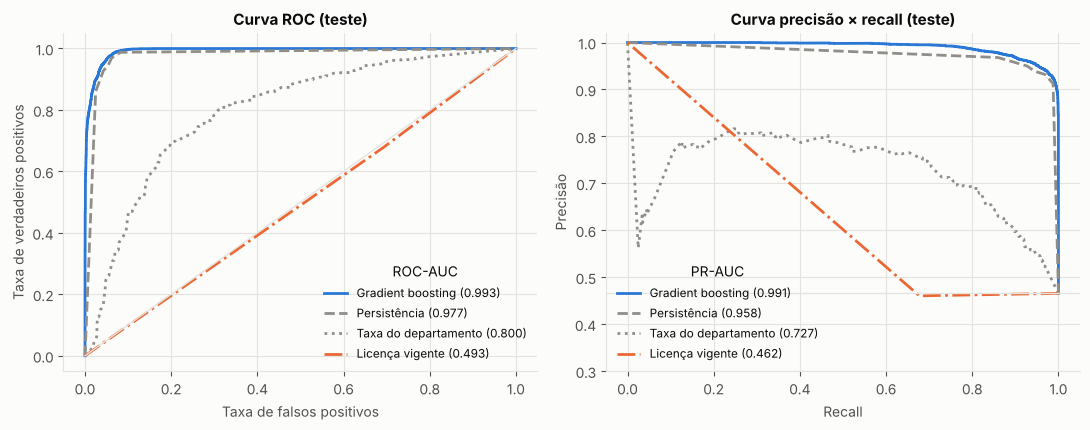

In [12]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.4))
estilos = [(ESCOLHIDO, AZUL, '-'), ('Persistência', CINZA, '--'), ('Taxa do departamento', CINZA, ':'), ('Licença vigente', LARANJA, '-.')]
for nome, cor, ls in estilos:
    fpr, tpr, _ = roc_curve(y_te, prob_teste[nome])
    a1.plot(fpr, tpr, color=cor, ls=ls, label=f'{nome} ({roc_auc_score(y_te, prob_teste[nome]):.3f})')
    pr, rc, _ = precision_recall_curve(y_te, prob_teste[nome])
    a2.plot(rc, pr, color=cor, ls=ls, label=f'{nome} ({average_precision_score(y_te, prob_teste[nome]):.3f})')
a1.plot([0, 1], [0, 1], color=GRADE, lw=1)
a1.set(title='Curva ROC (teste)', xlabel='Taxa de falsos positivos', ylabel='Taxa de verdadeiros positivos')
a2.axhline(y_te.mean(), color=GRADE, lw=1)
a2.set(title='Curva precisão × recall (teste)', xlabel='Recall', ylabel='Precisão', ylim=(0.3, 1.02))
a1.legend(title='ROC-AUC', loc='lower right', fontsize=8.5); a2.legend(title='PR-AUC', loc='lower left', fontsize=8.5)
fig.tight_layout(); fig.savefig(FIG / 'fig1_curvas_teste.png', dpi=150); plt.show()

### Onde o modelo ganha da persistência

A persistência acerta quase sempre que o padrão se repete. O teste por subgrupo mostra onde ela falha e se o modelo compensa.

In [13]:
grupos = {
    'Todos': np.ones(len(teste), bool),
    'Não usou no mês m': teste.usou.values == 0,
    'Usou no mês m': teste.usou.values == 1,
    'Mês-alvo de férias (jul)': teste.mes_alvo_ferias.values == 1,
    'Até 6 meses de casa': teste.meses_de_casa.values <= 6,
    'Com licença vigente': teste.licenca_vigente.values == 1,
    'Sem licença vigente': teste.licenca_vigente.values == 0,
}
sub = []
for nome, m in grupos.items():
    yy = y_te[m]
    sub.append(dict(subgrupo=nome, linhas=int(m.sum()), taxa_de_uso=yy.mean(),
                    **{f'PR-AUC {k}': average_precision_score(yy, prob_teste[k][m]) for k in (ESCOLHIDO, 'Persistência')},
                    **{f'ROC-AUC {k}': roc_auc_score(yy, prob_teste[k][m]) if len(set(yy)) > 1 else np.nan for k in (ESCOLHIDO, 'Persistência')}))
subgrupos = pd.DataFrame(sub).set_index('subgrupo')
subgrupos.to_csv(SAIDA / 'metricas_subgrupos.csv')
subgrupos.round(3)

,linhas,taxa_de_uso,PR-AUC Gradient boosting,PR-AUC Persistência,ROC-AUC Gradient boosting,ROC-AUC Persistência
subgrupo,,,,,,
Todos,13625,0.466,0.991,0.958,0.993,0.977
Não usou no mês m,7246,0.049,0.727,0.520,0.984,0.877
Usou no mês m,6379,0.939,0.994,0.966,0.917,0.728
Mês-alvo de férias (jul),6821,0.461,0.989,0.951,0.991,0.974
Até 6 meses de casa,972,0.376,0.980,0.918,0.989,0.964
Com licença vigente,9334,0.460,0.990,0.957,0.992,0.977
Sem licença vigente,4291,0.477,0.992,0.961,0.993,0.977


O ganho do modelo está nos casos em que a regra simples não tem informação:

- **Quem não usou no mês *m*** (53% das linhas e 5% de retomada): a persistência só consegue ordenar essas pessoas pelos meses anteriores e chega a PR-AUC de 0,520. O modelo chega a 0,727, porque cruza o uso das outras ferramentas com a recência.
- **Quem usou no mês *m*:** o modelo separa muito melhor quem vai parar (ROC-AUC de 0,917 contra 0,728).
- **Julho**, mês de férias, e **recém-contratados** (até 6 meses de casa): o desempenho se mantém.

### Calibração

A probabilidade vira **valor esperado** de uso na alocação de licenças. Por isso precisa ser confiável: entre as linhas com probabilidade de 70%, cerca de 70% devem usar.

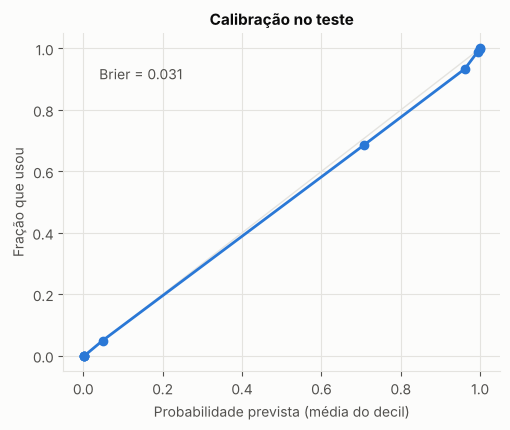

In [14]:
fig, ax = plt.subplots(figsize=(5.2, 4.4))
frac, media = calibration_curve(y_te, p_final, n_bins=10, strategy='quantile')
ax.plot([0, 1], [0, 1], color=GRADE, lw=1)
ax.plot(media, frac, color=AZUL, marker='o', ms=6, label=ESCOLHIDO)
ax.set(title='Calibração no teste', xlabel='Probabilidade prevista (média do decil)', ylabel='Fração que usou')
ax.text(0.04, 0.9, f'Brier = {brier_score_loss(y_te, p_final):.3f}', color=TINTA2)
fig.tight_layout(); fig.savefig(FIG / 'fig2_calibracao.png', dpi=150); plt.show()

Os decis ficam sobre a diagonal: entre as linhas com probabilidade prevista em torno de 70%, 68% usaram a ferramenta. A probabilidade pode ser usada diretamente como valor esperado.

### Estabilidade: validação mês a mês (origem móvel)

Para cada mês-alvo de fevereiro a julho de 2026, o modelo escolhido é reajustado com **todos os meses anteriores** e avaliado só naquele mês. Assim a avaliação usa seis cortes diferentes, não um único.

In [15]:
backtest = []
for alvo in pd.period_range('2026-02', '2026-07', freq='M'):
    tr, te = base[base.mes_alvo < alvo], base[base.mes_alvo == alvo]
    m = fabricas[ESCOLHIDO][melhores.loc[ESCOLHIDO, 'hiperparametros']]().fit(tr[COLS], tr.usa_proximo_mes.values)
    p = m.predict_proba(te[COLS])[:, 1]
    pp = baselines['Persistência'](te)
    backtest.append(dict(mes_alvo=str(alvo), linhas=len(te), taxa_de_uso=te.usa_proximo_mes.mean(),
                         pr_auc_modelo=average_precision_score(te.usa_proximo_mes, p), pr_auc_persistencia=average_precision_score(te.usa_proximo_mes, pp),
                         roc_auc_modelo=roc_auc_score(te.usa_proximo_mes, p), roc_auc_persistencia=roc_auc_score(te.usa_proximo_mes, pp),
                         brier_modelo=brier_score_loss(te.usa_proximo_mes, p)))
backtest = pd.DataFrame(backtest)
backtest.to_csv(SAIDA / 'backtest_mensal.csv', index=False)
backtest.round(4)

,mes_alvo,linhas,taxa_de_uso,pr_auc_modelo,pr_auc_persistencia,roc_auc_modelo,roc_auc_persistencia,brier_modelo
0,2026-02,6551,0.4616,0.9872,0.9504,0.9883,0.9669,0.0375
1,2026-03,6610,0.4638,0.9874,0.9536,0.9891,0.9703,0.0353
2,2026-04,6669,0.4680,0.9902,0.9611,0.9916,0.9760,0.0328
3,2026-05,6736,0.4675,0.9912,0.9556,0.9928,0.9752,0.0304
4,2026-06,6804,0.4702,0.9927,0.9655,0.9938,0.9798,0.0291
5,2026-07,6821,0.4611,0.9888,0.9511,0.9913,0.9740,0.0336


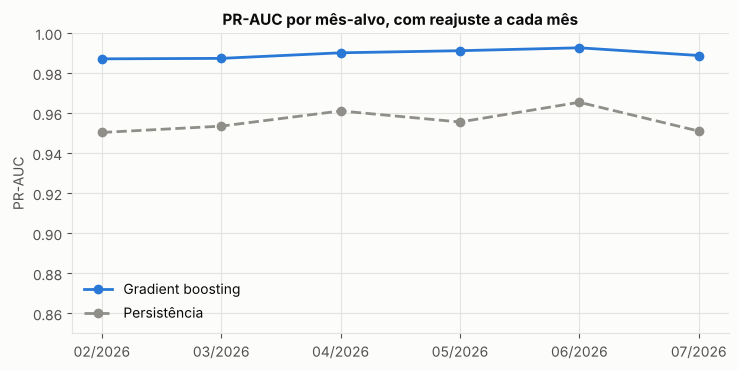

In [16]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
x = np.arange(len(backtest))
ax.plot(x, backtest.pr_auc_modelo, color=AZUL, marker='o', ms=6, label=ESCOLHIDO)
ax.plot(x, backtest.pr_auc_persistencia, color=CINZA, ls='--', marker='o', ms=6, label='Persistência')
ax.set_xticks(x, [m[5:] + '/' + m[:4] for m in backtest.mes_alvo])
ax.set(title='PR-AUC por mês-alvo, com reajuste a cada mês', ylabel='PR-AUC', ylim=(0.85, 1.0))
ax.legend(loc='lower left')
fig.tight_layout(); fig.savefig(FIG / 'fig3_backtest_mensal.png', dpi=150); plt.show()

Nos seis meses, o modelo supera a persistência: PR-AUC de 0,987 a 0,993, contra 0,950 a 0,965. Isso vale também em julho, mês de férias. O resultado não depende do corte escolhido para o teste.

## 10. Interpretação: o que o modelo usa

A **importância por permutação** embaralha uma variável de cada vez no teste e mede quanto a PR-AUC cai. Ela é calculada sobre as colunas originais, então funciona igual para as três famílias.

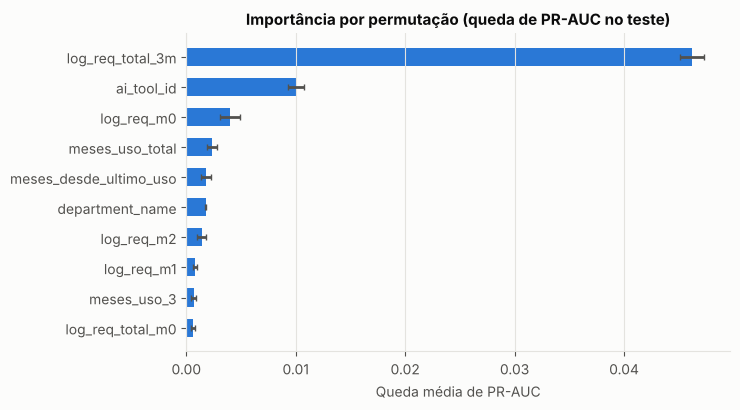

,variavel,queda_pr_auc,desvio
8,log_req_total_3m,0.0462,0.0011
18,ai_tool_id,0.0100,0.0007
0,log_req_m0,0.0040,0.0009
4,meses_uso_total,0.0024,0.0004
5,meses_desde_ultimo_uso,0.0018,0.0005
21,department_name,0.0018,0.0001
2,log_req_m2,0.0014,0.0004
1,log_req_m1,0.0008,0.0002
3,meses_uso_3,0.0007,0.0002
7,log_req_total_m0,0.0006,0.0002


In [17]:
amostra = teste.sample(6000, random_state=SEED)
imp = permutation_importance(finais[ESCOLHIDO], amostra[COLS], amostra.usa_proximo_mes.values, scoring='average_precision',
                             n_repeats=5, random_state=SEED, n_jobs=1)
importancia = pd.DataFrame({'variavel': COLS, 'queda_pr_auc': imp.importances_mean, 'desvio': imp.importances_std}).sort_values('queda_pr_auc', ascending=False)
importancia.to_csv(SAIDA / 'importancia_permutacao.csv', index=False)
top = importancia.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.barh(top.variavel, top.queda_pr_auc, color=AZUL, height=0.6, xerr=top.desvio, ecolor=TINTA2, capsize=2)
ax.set(title='Importância por permutação (queda de PR-AUC no teste)', xlabel='Queda média de PR-AUC')
ax.grid(axis='y', visible=False)
fig.tight_layout(); fig.savefig(FIG / 'fig4_importancia.png', dpi=150); plt.show()
importancia.head(10).round(4)

- **O uso geral de IA nos últimos três meses domina.** Quem usa IA com frequência tende a usar qualquer ferramenta disponível.
- Depois vêm a própria ferramenta, o uso dela no mês e a recência.
- **Licença vigente, liberação pela governança e cursos não pesam nada.** É o reflexo da base: licença e uso são independentes (seção 3), e a Estatística Multivariada não encontrou efeito da capacitação no uso depois dos controles (H1).

Numa empresa real, em que sem licença não há uso, a licença seria uma variável forte. A recomendação, porém, continuaria a mesma: tirar licença de quem não usa.

## 11. Aplicação: recomendação de licenças

### Simulação no teste

Para cada empresa, ferramenta e mês de teste, o **número de assentos é mantido**: são as licenças vigentes naquele mês. Muda só quem os recebe. Três regras são comparadas:

- **Atual:** quem tem licença vigente.
- **Persistência:** quem usou no mês anterior.
- **Modelo:** as maiores probabilidades.

Duas métricas:

- **Aproveitamento:** fração dos assentos usada no mês.
- **Cobertura:** fração das pessoas que usaram a ferramenta e tinham assento.

In [18]:
sim = teste.assign(p=p_final, persist=baselines['Persistência'](teste) + 1e-6 * np.random.default_rng(SEED).random(len(teste)))
linhas = []
for (c, t, m), s in sim.groupby(['company_id', 'ai_tool_id', 'mes_alvo']):
    k = int(s.licenca_vigente.sum())
    if k == 0 or s.usa_proximo_mes.sum() == 0:
        continue
    usuarios = s.usa_proximo_mes.sum()
    for regra, escolhidos in [('Atual (licença vigente)', s[s.licenca_vigente == 1]), ('Persistência', s.nlargest(k, 'persist')), ('Modelo', s.nlargest(k, 'p'))]:
        linhas.append(dict(empresa=c, ferramenta=t, mes=str(m), regra=regra, assentos=k, usuarios=usuarios, usados=escolhidos.usa_proximo_mes.sum()))
simulacao = pd.DataFrame(linhas)
resumo_sim = simulacao.groupby('regra', sort=False)[['assentos', 'usuarios', 'usados']].sum()
resumo_sim['aproveitamento'] = resumo_sim.usados / resumo_sim.assentos
resumo_sim['cobertura'] = resumo_sim.usados / resumo_sim.usuarios
resumo_sim.to_csv(SAIDA / 'simulacao_realocacao_teste.csv')
resumo_sim.round(3)

,assentos,usuarios,usados,aproveitamento,cobertura
regra,,,,,
Atual (licença vigente),9334,6344,4297,0.460,0.677
Persistência,9334,6344,5435,0.582,0.857
Modelo,9334,6344,5485,0.588,0.865


Com o mesmo número de assentos, entregá-los a quem o modelo indica eleva o **aproveitamento de 46% para 59%** e a **cobertura de 68% para 87%**.

O aproveitamento máximo possível seria 68%, porque há mais assentos (9.334) do que usuários (6.344) nos meses de teste. O modelo chega a 86% desse máximo.

A persistência chega perto, com 58% e 86%. Para alocar licenças, a regra simples já captura a maior parte do ganho. O modelo acrescenta duas coisas:
- o ganho nos casos de retomada;
- uma **probabilidade calibrada**, que a Pesquisa Operacional pode usar como valor esperado de cada licença.

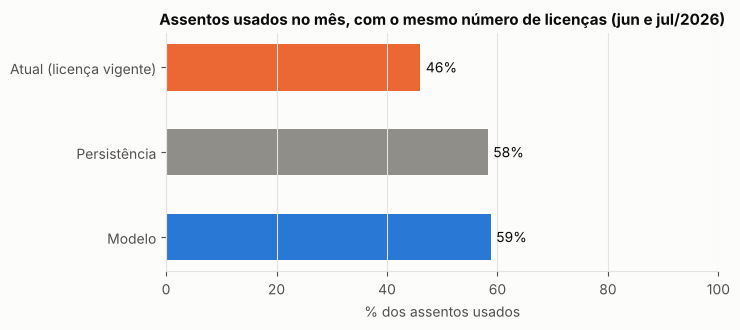

In [19]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
regras = resumo_sim.index.tolist()
cores = [LARANJA, CINZA, AZUL]
y = np.arange(len(regras))
ax.barh(y, resumo_sim.aproveitamento * 100, color=cores, height=0.55)
for i, v in enumerate(resumo_sim.aproveitamento * 100):
    ax.text(v + 1, i, f'{v:.0f}%', va='center', color=TINTA)
ax.set_yticks(y, regras)
ax.set(title='Assentos usados no mês, com o mesmo número de licenças (jun e jul/2026)', xlabel='% dos assentos usados', xlim=(0, 100))
ax.grid(axis='y', visible=False); ax.invert_yaxis()
fig.tight_layout(); fig.savefig(FIG / 'fig5_realocacao.png', dpi=150); plt.show()

### Recomendação para agosto de 2026

O modelo final é reajustado com **todos** os meses-alvo disponíveis (até jul/2026). A previsão de agosto usa as variáveis de julho.

- **Assentos de agosto:** licenças com status "Ativa" e vigentes em agosto, o mesmo critério do faturamento.
- **Ferramentas excluídas:** as sem nenhum uso na empresa nos últimos três meses, o que tira a ferramenta descontinuada (T15).
- **Preço do assento:** custo faturado em R$ dividido pelas licenças faturadas em jul/2026, por empresa e ferramenta.

In [20]:
modelo_final = fabricas[ESCOLHIDO][melhores.loc[ESCOLHIDO, 'hiperparametros']]().fit(base[COLS], base.usa_proximo_mes.values)
futuro = futuro.copy()
futuro['mes_alvo_ferias'] = 0                     # agosto não é mês de férias
futuro['prob_uso_ago2026'] = modelo_final.predict_proba(futuro[COLS])[:, 1]

ago = pd.Period('2026-08', 'M')
lic['_ativa_ago'] = (lic.license_status == 'Ativa') & (lic._ini <= ago) & (lic._fim.isna() | (lic._fim >= ago))
futuro = futuro.merge(lic.loc[lic._ativa_ago, ['employee_id', 'ai_tool_id']].assign(assento_ago=1), on=['employee_id', 'ai_tool_id'], how='left').fillna({'assento_ago': 0})
recentes = uso[uso.mes >= pd.Period('2026-05', 'M')][['company_id', 'ai_tool_id']].drop_duplicates().assign(ativa=1)
futuro = futuro.merge(recentes, on=['company_id', 'ai_tool_id'], how='left')
futuro = futuro[futuro.ativa == 1].drop(columns='ativa')

fat = ler('ai_billing')
preco = (fat[(fat.billing_month == '2026-07') & (fat.currency == 'BRL')].groupby(['company_id', 'ai_tool_id'])
         .agg(custo=('total_cost', 'sum'), assentos=('usage_quantity', 'sum')))
preco = (preco.custo / preco.assentos).rename('preco_assento_brl').reset_index()
futuro = futuro.merge(preco, on=['company_id', 'ai_tool_id'], how='left')

RISCO, CANDIDATO = 0.2, 0.8
futuro['recomendacao'] = np.select(
    [(futuro.assento_ago == 1) & (futuro.prob_uso_ago2026 < RISCO), (futuro.assento_ago == 0) & (futuro.prob_uso_ago2026 >= CANDIDATO)],
    ['Revisar: assento com risco de ociosidade', 'Considerar: uso provável sem assento'], 'Manter')
cols_saida = ['employee_id', 'company_id', 'department_name', 'seniority', 'ai_tool_id', 'tool_category', 'assento_ago', 'prob_uso_ago2026', 'recomendacao', 'preco_assento_brl']
futuro[cols_saida].sort_values(['company_id', 'ai_tool_id', 'prob_uso_ago2026'], ascending=[True, True, False]).round(4).to_csv(SAIDA / 'recomendacao_ago2026.csv', index=False)

por_empresa = futuro.groupby('company_id').apply(lambda d: pd.Series({
    'assentos_ago': int(d.assento_ago.sum()),
    'usuarios_esperados': d.prob_uso_ago2026.sum(),
    'assentos_ociosos_esperados': (d.assento_ago * (1 - d.prob_uso_ago2026)).sum(),
    'revisar_risco_ociosidade': int((d.recomendacao == 'Revisar: assento com risco de ociosidade').sum()),
    'custo_mensal_revisar_brl': d.loc[d.recomendacao == 'Revisar: assento com risco de ociosidade', 'preco_assento_brl'].sum(),
    'considerar_sem_assento': int((d.recomendacao == 'Considerar: uso provável sem assento').sum()),
}), include_groups=False).merge(comp.set_index('company_id')[['company_name']], left_index=True, right_index=True)
por_empresa.to_csv(SAIDA / 'recomendacao_ago2026_por_empresa.csv')
tot = por_empresa.drop(columns='company_name').sum()
br = lambda v: f'{v:,.0f}'.replace(',', '.')
print(f'Assentos ativos em ago/2026: {br(tot.assentos_ago)} | ociosos esperados: {br(tot.assentos_ociosos_esperados)} '
      f'| a revisar (p < {RISCO}): {br(tot.revisar_risco_ociosidade)}, custando R$ {br(tot.custo_mensal_revisar_brl)} por mês '
      f'| uso provável sem assento (p ≥ {CANDIDATO}): {br(tot.considerar_sem_assento)}')
por_empresa.round(1)

Assentos ativos em ago/2026: 2.880 | ociosos esperados: 1.795 | a revisar (p < 0.2): 1.707, custando R$ 219.447 por mês | uso provável sem assento (p ≥ 0.8): 2.032


,assentos_ago,usuarios_esperados,assentos_ociosos_esperados,revisar_risco_ociosidade,custo_mensal_revisar_brl,considerar_sem_assento,company_name
company_id,,,,,,,
C01,266.0,1186.7,73.2,63.0,11574.1,957.0,NexoCode Solucoes
C02,122.0,405.9,39.0,35.0,5603.4,312.0,Vortice Software
C03,87.0,101.4,31.5,25.0,3408.7,40.0,Piloto Digital Sistemas
C04,106.0,282.1,38.4,32.0,3333.0,200.0,Cronos Tech Labs
C05,73.0,39.1,40.4,35.0,4229.3,6.0,ByteFlow Engenharia de Software
C06,390.0,237.6,243.2,236.0,42796.9,85.0,Banco Alterosa S.A.
C07,125.0,35.7,92.2,88.0,10202.9,3.0,Capital Sul Investimentos
C08,57.0,24.5,38.2,37.0,6628.2,5.0,Fincredi Solucoes Financeiras
C09,577.0,115.6,467.9,454.0,52264.6,6.0,Metalurgica Vale Forte


**Agosto de 2026, todas as empresas:**

- **Assentos ativos:** 2.880. Desses, cerca de **1.795 devem ficar ociosos** (soma de 1 − probabilidade de uso).
- **Para revisar:** 1.707 assentos com probabilidade de uso abaixo de 20%, que custam cerca de **R$ 219 mil por mês**.
- **Para considerar:** 2.032 pares colaborador × ferramenta com probabilidade de uso acima de 80% e sem assento.

O padrão muda com o setor:

- **Indústria, varejo e financeiro** concentram os assentos ociosos. A Metalúrgica Vale Forte tem 577 assentos para cerca de 116 usuários esperados.
- **Tecnologia e marketing** têm mais uso esperado do que assentos. A NexoCode tem 266 assentos e cerca de 1.190 usuários esperados.

A lista completa, por colaborador e ferramenta, está em `resultados/recomendacao_ago2026.csv`. A decisão de quem recebe cada assento, dentro do orçamento e da governança, é do modelo da Pesquisa Operacional.

## 12. Conclusões

Os números citados abaixo saem das tabelas acima e são conferidos no fim do notebook.

In [21]:
r = resultado_teste
print(f"Modelo escolhido: {ESCOLHIDO} ({melhores.loc[ESCOLHIDO, 'hiperparametros']})")
print(f"Teste — PR-AUC {r.loc[ESCOLHIDO, 'pr_auc']:.3f} (persistência {r.loc['Persistência', 'pr_auc']:.3f}); "
      f"ROC-AUC {r.loc[ESCOLHIDO, 'roc_auc']:.3f} (persistência {r.loc['Persistência', 'roc_auc']:.3f}); "
      f"Brier {r.loc[ESCOLHIDO, 'brier']:.3f} (persistência {r.loc['Persistência', 'brier']:.3f})")
print(f"Licença vigente como previsor: ROC-AUC {r.loc['Licença vigente', 'roc_auc']:.3f}")
s = subgrupos.loc['Não usou no mês m']
print(f"Quem não usou no mês m: PR-AUC {s[f'PR-AUC {ESCOLHIDO}']:.3f} contra {s['PR-AUC Persistência']:.3f} da persistência")
print(f"Realocação no teste: aproveitamento {resumo_sim.loc['Atual (licença vigente)', 'aproveitamento']:.1%} (atual) → "
      f"{resumo_sim.loc['Modelo', 'aproveitamento']:.1%} (modelo); cobertura {resumo_sim.loc['Atual (licença vigente)', 'cobertura']:.1%} → {resumo_sim.loc['Modelo', 'cobertura']:.1%}")
print(f'Tempo total: {time.time() - inicio:.0f} s')

Modelo escolhido: Gradient boosting (learning_rate=0.05, max_leaf_nodes=15, l2=1.0)
Teste — PR-AUC 0.991 (persistência 0.958); ROC-AUC 0.993 (persistência 0.977); Brier 0.031 (persistência 0.051)
Licença vigente como previsor: ROC-AUC 0.493
Quem não usou no mês m: PR-AUC 0.727 contra 0.520 da persistência
Realocação no teste: aproveitamento 46.0% (atual) → 58.8% (modelo); cobertura 67.7% → 86.5%
Tempo total: 142 s


### Resumo

| Pergunta | Resposta |
|---|---|
| O modelo prevê bem? | Sim. No teste (jun e jul/2026), a PR-AUC é 0,991, o ROC-AUC é 0,993 e o Brier é 0,031, com validação temporal e estabilidade nos seis meses do backtest |
| Supera regras simples? | Sim, mas a persistência já é forte (PR-AUC de 0,958). O ganho está em quem não usou no mês: PR-AUC de 0,727 contra 0,520 |
| A licença atual indica uso? | Não. Como previsor, o ROC-AUC dela é 0,493 |
| Para que serve? | Realocar os mesmos assentos eleva o aproveitamento de 46% para 59% e a cobertura dos usuários de 68% para 87%. Em agosto de 2026, 1.707 assentos (cerca de R$ 219 mil por mês) têm probabilidade de uso abaixo de 20% |

**Limitações**
- A base é sintética: o nível de atividade de cada pessoa é fixo durante todo o período. Por isso o uso é tão persistente e as métricas são tão altas. Em dados reais, espera-se mais variação e métricas menores.
- Licença e uso são independentes na base. Em dados reais, a licença seria um previsor forte e o ganho da realocação seria menor.
- O modelo prevê **se** a pessoa usa, não **quanto** usa. A próxima versão pode prever o volume, que é o valor em usuários-equivalentes (UE) usado na Pesquisa Operacional.

**Próximo passo no produto:** expor a probabilidade numa rota da API, para que as análises de gestão mostrem o alerta "licença com risco de ociosidade" e a recomendação de realocação.